In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- UCI (household) ---
uci_X_train = np.load("../data/processed/X_train.npy")
uci_y_train = np.load("../data/processed/y_train.npy")
uci_X_test  = np.load("../data/processed/X_test.npy")
uci_y_test  = np.load("../data/processed/y_test.npy")

# --- ELIA (grid) ---
elia_X_train = np.load("../data/processed/elia_X_train.npy")
elia_y_train = np.load("../data/processed/elia_y_train.npy")
elia_X_test  = np.load("../data/processed/elia_X_test.npy")
elia_y_test  = np.load("../data/processed/elia_y_test.npy")

print(f"UCI  train: {uci_X_train.shape}, test: {uci_X_test.shape}")
print(f"ELIA train: {elia_X_train.shape}, test: {elia_X_test.shape}")

UCI  train: (23900, 24), test: (5122, 24)
ELIA train: (33700, 24), test: (7222, 24)


In [2]:
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100

def evaluate(name, y_true, y_pred, latency_ms):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    m    = mape(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    return {
        "model": name,
        "RMSE": float(rmse),
        "MAE":  float(mae),
        "MAPE": float(m),
        "R2":   float(r2),
        "latency_ms_per_sample": float(latency_ms),
    }

In [3]:
import time

rf_uci = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf_uci.fit(uci_X_train, uci_y_train)

start = time.perf_counter()
uci_pred = rf_uci.predict(uci_X_test)
uci_latency = ((time.perf_counter() - start) / len(uci_X_test)) * 1000

uci_metrics = evaluate("RF (UCI household)", uci_y_test, uci_pred, uci_latency)
print("UCI:", uci_metrics)

UCI: {'model': 'RF (UCI household)', 'RMSE': 0.4864631941953724, 'MAE': 0.3342665846028031, 'MAPE': 44.862333906875634, 'R2': 0.5301624105454336, 'latency_ms_per_sample': 0.04853580632747148}


In [4]:
rf_elia = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf_elia.fit(elia_X_train, elia_y_train)

start = time.perf_counter()
elia_pred = rf_elia.predict(elia_X_test)
elia_latency = ((time.perf_counter() - start) / len(elia_X_test)) * 1000

elia_metrics = evaluate("RF (ELIA grid)", elia_y_test, elia_pred, elia_latency)
print("ELIA:", elia_metrics)

ELIA: {'model': 'RF (ELIA grid)', 'RMSE': 191.69633654498392, 'MAE': 143.9811006635865, 'MAPE': 1.502305497888163, 'R2': 0.9800397598327099, 'latency_ms_per_sample': 0.029938410411883384}


In [5]:
results_df = pd.DataFrame([uci_metrics, elia_metrics])
results_df = results_df.set_index("model")
print("\n=== Baseline Comparison: Household vs Grid ===")
display(results_df.round(4))


=== Baseline Comparison: Household vs Grid ===


,RMSE,MAE,MAPE,R2,latency_ms_per_sample
model,,,,,
RF (UCI household),0.4865,0.3343,44.8623,0.5302,0.0485
RF (ELIA grid),191.6963,143.9811,1.5023,0.9800,0.0299


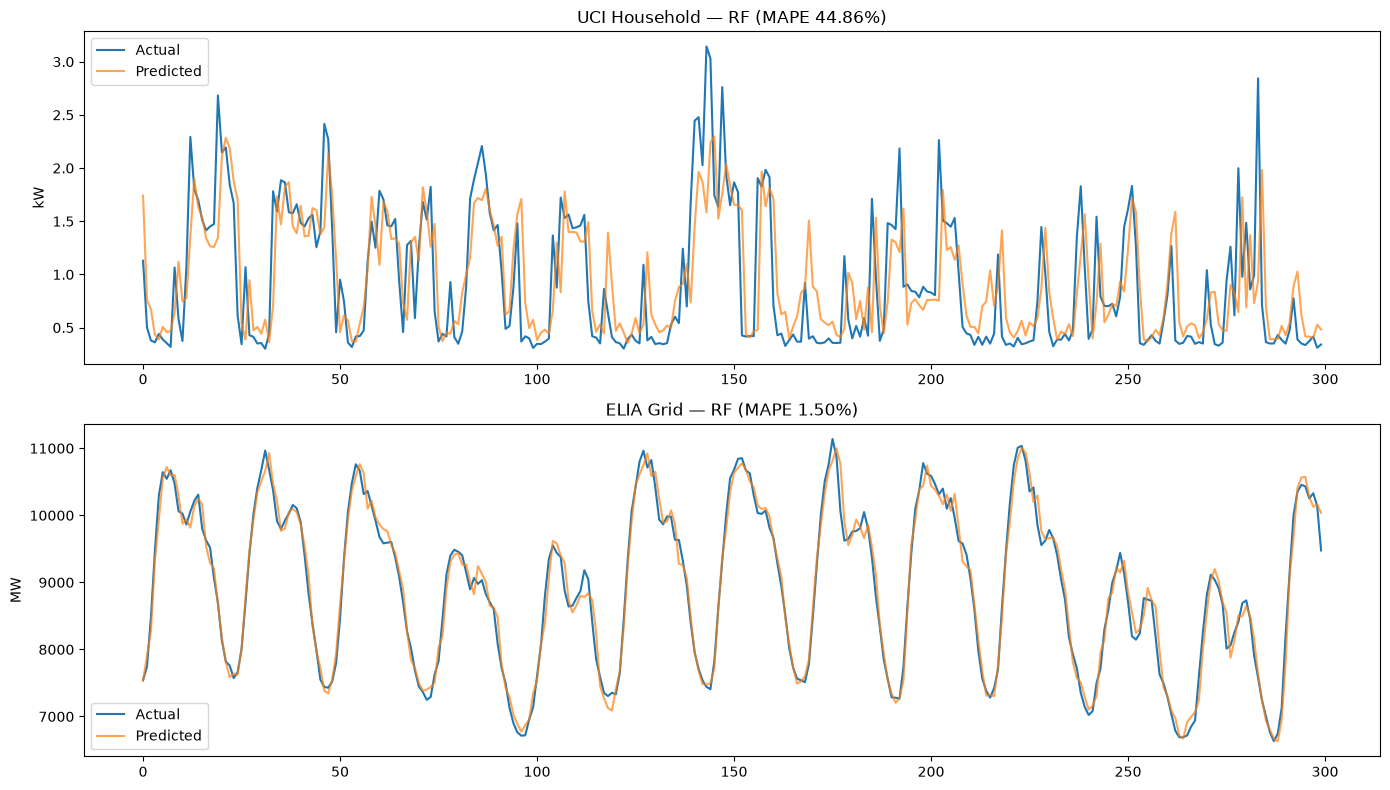

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# UCI
axes[0].plot(uci_y_test[:300], label="Actual", linewidth=1.5)
axes[0].plot(uci_pred[:300], label="Predicted", linewidth=1.5, alpha=0.7)
axes[0].set_title(f"UCI Household — RF (MAPE {uci_metrics['MAPE']:.2f}%)")
axes[0].set_ylabel("kW")
axes[0].legend()

# ELIA
axes[1].plot(elia_y_test[:300], label="Actual", linewidth=1.5)
axes[1].plot(elia_pred[:300], label="Predicted", linewidth=1.5, alpha=0.7)
axes[1].set_title(f"ELIA Grid — RF (MAPE {elia_metrics['MAPE']:.2f}%)")
axes[1].set_ylabel("MW")
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
comparison = {
    "uci_household": uci_metrics,
    "elia_grid": elia_metrics,
}

with open("../data/processed/baseline_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)

print("Saved baseline_comparison.json")

Saved baseline_comparison.json
